# Customer Churn Prediction
MCA Data Science Project
Predicting telecom customer churn using Python and scikit-learn

This version includes hyperparameter tuning, feature engineering, and threshold tuning.
The goal is to improve accuracy while keeping good recall for churners.

## 1. Import Libraries

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
)
from imblearn.over_sampling import SMOTE

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported.")

Libraries imported.


## 2. Load Dataset
Make sure `Telco-Customer-Churn.csv` is in the same folder as this notebook.

In [18]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Quick Exploration
Check data types, missing values, and basic stats.

In [19]:
df.info()
print()
print("Missing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 4. Data Cleaning
- `TotalCharges` has blank spaces → convert to numeric
- Drop rows with missing values
- Remove `customerID` — it is just an ID, not a feature

In [20]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna()
df = df.drop("customerID", axis=1)

print("After cleaning:", df.shape)
df.head()

After cleaning: (7032, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 5. Feature Engineering
Create new columns from existing ones so the model can learn better patterns.

- `tenure_per_charge`: tenure divided by monthly charges (how long per rupee spent)
- `services_count`: count of active services (Internet, Security, Backup, etc.)
- `has_multiple_services`: 1 if customer uses more than one paid service

In [21]:
# tenure per monthly charge
df["tenure_per_charge"] = df["tenure"] / (df["MonthlyCharges"] + 1)

# count how many paid services the customer uses
service_cols = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

def count_active_services(row):
    count = 0
    for col in service_cols:
        if col in row and str(row[col]).strip().lower() in ["yes", "1", "true"]:
            count += 1
    return count

df["services_count"] = df.apply(count_active_services, axis=1)

# binary flag: uses more than one service
df["has_multiple_services"] = (df["services_count"] > 1).astype(int)

print("New features added:")
print(df[['tenure_per_charge', 'services_count', 'has_multiple_services']].head())
print("\nShape after feature engineering:", df.shape)

New features added:
   tenure_per_charge  services_count  has_multiple_services
0           0.032415               1                      0
1           0.586713               3                      1
2           0.036463               3                      1
3           1.039261               3                      1
4           0.027894               1                      0

Shape after feature engineering: (7032, 23)


## 6. Encode Target & Features
- Map `Churn` to 0/1
- One-hot encode categorical columns
- Convert everything to int for modeling

In [22]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

df = pd.get_dummies(df, drop_first=True)
df = df.astype(int)

print("Encoded shape:", df.shape)
df.head()

Encoded shape: (7032, 34)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,tenure_per_charge,services_count,has_multiple_services,gender_Male,Partner_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29,29,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56,1889,0,0,3,1,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53,108,1,0,3,1,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42,1840,0,1,3,1,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70,151,1,0,1,0,0,0,...,0,0,0,0,0,0,1,0,1,0


## 7. Train-Test Split
Use `stratify=y` so the train/test split keeps the same churn ratio as the full data.

In [23]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nChurn ratio in full data:")
print(df["Churn"].value_counts(normalize=True))

Train shape: (5625, 33)
Test shape: (1407, 33)

Churn ratio in full data:
Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64


## 8. Handle Class Imbalance
Churn is the minority class (~26%). Apply SMOTE **only on training data** to avoid data leakage.

In [24]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_sm).value_counts())

Before SMOTE:
Churn
0    4130
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4130
1    4130
Name: count, dtype: int64


## 9. Train Models
- Decision Tree (baseline)
- Random Forest (no SMOTE)
- Random Forest with SMOTE
- Random Forest with SMOTE + GridSearch tuning

In [25]:
# Decision Tree
dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Random Forest (no SMOTE)
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Random Forest with SMOTE
rf_sm = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_sm.fit(X_train_sm, y_train_sm)
y_pred_rf_sm = rf_sm.predict(X_test)

print("Base models trained.")

Base models trained.


## 10. Hyperparameter Tuning (GridSearchCV)
Try different `n_estimators`, `max_depth`, etc. to find the best Random Forest.
We use SMOTE data here because it gave better recall for churners.

In [26]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

print("Tuning... this may take a minute.")
grid.fit(X_train_sm, y_train_sm)

print("Best parameters:", grid.best_params_)
best_rf = grid.best_estimator_
y_pred_best = best_rf.predict(X_test)
y_proba_best = best_rf.predict_proba(X_test)[:, 1]

Tuning... this may take a minute.
Best parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}


## 11. Threshold Tuning
By default, predict_proba >= 0.5 → class 1.
We can try a lower threshold (e.g. 0.4) to catch more churners,
or check how accuracy changes.

In [27]:
y_proba_best = best_rf.predict_proba(X_test)[:, 1]

for threshold in [0.5, 0.45, 0.4, 0.35]:
    y_pred_thresh = (y_proba_best >= threshold).astype(int)
    acc = accuracy_score(y_test, y_pred_thresh)
    report = classification_report(y_test, y_pred_thresh, output_dict=True)
    recall_churn = report['1']['recall']
    print(f"Threshold {threshold}: Accuracy={acc:.4f}, Recall(churn)={recall_churn:.4f}")

Threshold 0.5: Accuracy=0.7569, Recall(churn)=0.6952
Threshold 0.45: Accuracy=0.7498, Recall(churn)=0.7567
Threshold 0.4: Accuracy=0.7342, Recall(churn)=0.7941
Threshold 0.35: Accuracy=0.7136, Recall(churn)=0.8316


## 12. Evaluate All Models
Print accuracy, ROC-AUC, classification report, and confusion matrix for each model.

In [28]:
def evaluate_model(name, y_true, y_pred, y_prob=None):
    print("=" * 50)
    print(f"MODEL: {name}")
    print("=" * 50)
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    if y_prob is not None:
        print("ROC-AUC  :", round(roc_auc_score(y_true, y_prob), 4))
    print()
    print("Classification Report:")
    print(classification_report(y_true, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))


evaluate_model("Decision Tree", y_test, y_pred_dt, dt.predict_proba(X_test)[:, 1])
evaluate_model("Random Forest", y_test, y_pred_rf, rf.predict_proba(X_test)[:, 1])
evaluate_model("Random Forest + SMOTE", y_test, y_pred_rf_sm, rf_sm.predict_proba(X_test)[:, 1])
evaluate_model("Random Forest + SMOTE + Tuned", y_pred_best, y_pred_best, y_proba_best)

MODEL: Decision Tree
Accuracy : 0.7569
ROC-AUC  : 0.751

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.84      1033
           1       0.54      0.52      0.53       374

    accuracy                           0.76      1407
   macro avg       0.69      0.68      0.68      1407
weighted avg       0.75      0.76      0.76      1407

Confusion Matrix:
[[869 164]
 [178 196]]
MODEL: Random Forest
Accuracy : 0.7825
ROC-AUC  : 0.8315

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.86      1033
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.68      0.70      1407
weighted avg       0.77      0.78      0.77      1407

Confusion Matrix:
[[923 110]
 [196 178]]
MODEL: Random Forest + SMOTE
Accuracy : 0.7591
ROC-AUC  : 0.82

Classification Report:
              pr

## 11. Visualizations
Confusion matrix for the best model and feature importance.

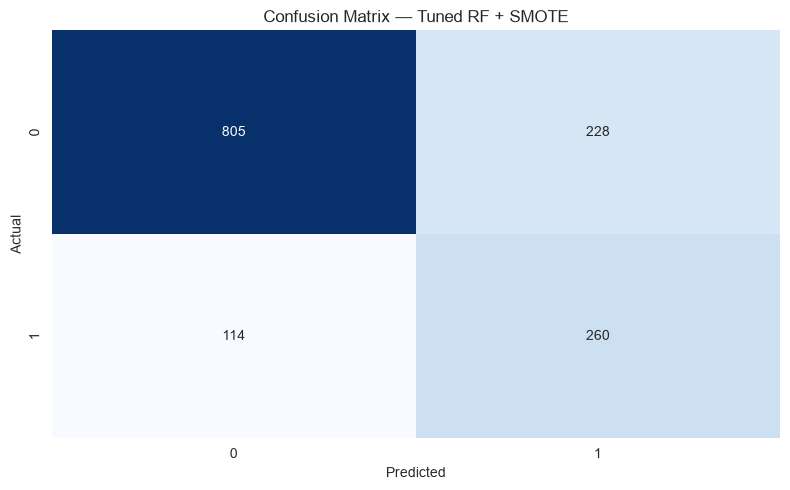

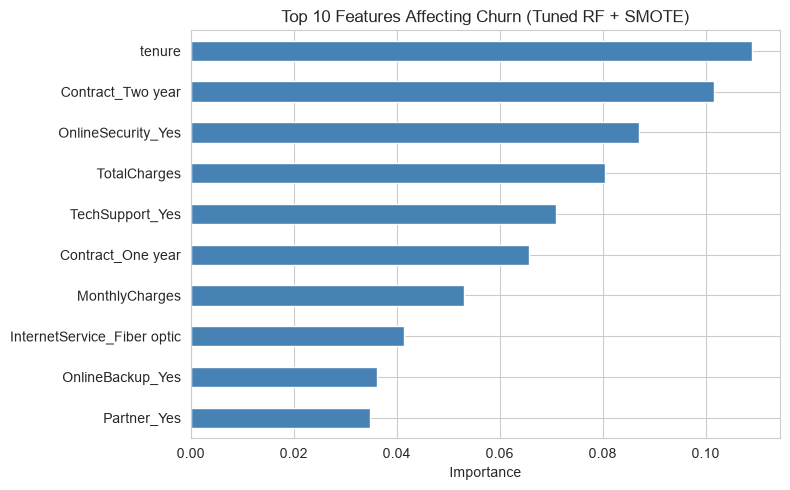

In [29]:
sns.heatmap(
    confusion_matrix(y_test, y_pred_best),
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
)
plt.title("Confusion Matrix — Tuned RF + SMOTE")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Feature importance from tuned model
feat_imp = pd.Series(best_rf.feature_importances_, index=X.columns)
feat_imp = feat_imp.sort_values(ascending=False).head(10)

feat_imp.plot(kind="barh", color="steelblue")
plt.title("Top 10 Features Affecting Churn (Tuned RF + SMOTE)")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [30]:
# Save best model for later use (deployment)
joblib.dump(best_rf, "churn_rf_smote_tuned.pkl")
print("Best model saved as churn_rf_smote_tuned.pkl")

Best model saved as churn_rf_smote_tuned.pkl


## Conclusion
- SMOTE lowered overall accuracy slightly but improved recall for the churn class.
- Hyperparameter tuning with GridSearchCV helped recover accuracy while keeping recall high.
- For churn retention, catching more at-risk customers is more valuable than avoiding false alarms,
  so Random Forest with SMOTE + tuning is selected as the final model.